# 02 · CSIC: comparing LR, RF and XGBoost + features.py

Notebook 01 built a TF-IDF + LR baseline. Here we answer two questions:
1. **Which model is best?** Logistic Regression, Random Forest or XGBoost.
2. **Which features are best?** TF-IDF alone, `features.py` alone, or both together.

That is 3 models × 3 feature sets = 9 experiments. We use 5-fold **cross-validation** so the result does not depend on one lucky split.

**Run 01 first**: this notebook reads `data/processed/csic_clean.csv`, which 01 writes.

In [ ]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from xgboost import XGBClassifier

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from ml.features import request_features

df = pd.read_csv(ROOT / 'data' / 'processed' / 'csic_clean.csv', keep_default_na=False)
print(df.shape)
df['label'].value_counts()

(25608, 6)


label
1    15964
0     9644
Name: count, dtype: int64

## 1. Compute features.py for each request

`request_features` takes the method, URL and body and returns about 50 numbers: request length, special-character counts, SQL/XSS keywords, etc. These features are **not tied to one site**, so they should also work on Juice Shop.

In [ ]:
t = time.time()
hand = pd.DataFrame([request_features(m, p, b) for m, p, b in zip(df['Method'], df['path'], df['body'])])
HAND_COLS = list(hand.columns)
data = pd.concat([df[['text_full', 'label']].rename(columns={'text_full': 'text'}), hand], axis=1)
print(f'{len(HAND_COLS)} hand features in {time.time() - t:.0f}s')
hand.describe().T[['mean', 'max']].round(2).head(15)

49 hand features in 3s


,mean,max
url_len,97.12,865.0
path_len,28.88,66.0
query_len,67.78,836.0
body_len,69.16,836.0
num_params,7.22,13.0
max_param_len,23.32,370.0
path_depth,3.03,6.0
num_dots_in_path,1.05,3.0
method_get,0.53,1.0
method_post,0.46,1.0


## 2. Build the models

- **TF-IDF:** same as 01 but with 10k columns for LR and 2k for RF/XGBoost (trees need much more memory per column).
- **Memory:** close Docker Desktop and other heavy apps while this runs.
- **Class weights:** the classes are unbalanced, so the smaller class gets more weight (`balanced` in LR and RF, `scale_pos_weight` in XGBoost).

In [ ]:
# fewer parallel jobs = less memory. If the kernel crashes, lower this to 1.
N_JOBS = 2
pos, neg = (data['label'] == 1).sum(), (data['label'] == 0).sum()

def make_features(kind, model):
    # trees need far more memory per column than LR, so they get fewer TF-IDF columns
    n_cols = 10_000 if model == 'LR' else 2_000
    tfidf = ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(2, 4), min_df=2,
                                      max_features=n_cols, sublinear_tf=True, dtype=np.float32), 'text')
    handf = ('hand', StandardScaler(), HAND_COLS)
    parts = {'tfidf': [tfidf], 'hand': [handf], 'both': [tfidf, handf]}[kind]
    return ColumnTransformer(parts)

MODELS = {
    'LR': lambda: LogisticRegression(max_iter=3000, class_weight='balanced'),
    'RF': lambda: RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=N_JOBS, random_state=42),
    'XGB': lambda: XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist', max_bin=32,
                                 scale_pos_weight=neg / pos, n_jobs=N_JOBS, random_state=42, eval_metric='logloss'),
}

def make_pipe(model, kind):
    return Pipeline([('features', make_features(kind, model)), ('model', MODELS[model]())])

## 3. Split the data

The test set (20%) is only used at the very end. Cross-validation runs on the training set only.

In [ ]:
train, test = train_test_split(data, test_size=0.2, stratify=data['label'], random_state=42)
X_train, y_train = train.drop(columns='label'), train['label']
X_test, y_test = test.drop(columns='label'), test['label']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
len(train), len(test)

(20486, 5122)

## 4. The 9 experiments (cross-validation)

This cell can take 10-20 minutes; RF is the slowest. Each result is saved to `data/processed/model_cv_results.csv` as soon as it finishes, so if the kernel crashes you can re-run this cell and it skips the experiments that are already done.

In [ ]:
RESULTS = ROOT / 'data' / 'processed' / 'model_cv_results.csv'
rows = pd.read_csv(RESULTS).to_dict('records') if RESULTS.exists() else []
done = {(r['features'], r['model']) for r in rows}
for kind in ['tfidf', 'hand', 'both']:
    for model in MODELS:
        if (kind, model) in done:
            continue
        t = time.time()
        try:
            scores = cross_val_score(make_pipe(model, kind), X_train, y_train, cv=cv, scoring='f1', n_jobs=1)
        except Exception as e:  # e.g. out of memory: record it and move on
            print(f'{kind:6} {model:4} FAILED: {type(e).__name__}')
            continue
        rows.append({'features': kind, 'model': model, 'f1_mean': scores.mean(), 'f1_std': scores.std(),
                     'seconds': time.time() - t})
        pd.DataFrame(rows).to_csv(RESULTS, index=False)
        print(f'{kind:6} {model:4} F1 = {scores.mean():.3f} ± {scores.std():.3f}  ({time.time() - t:.0f}s)')

results = pd.DataFrame(rows)
results.pivot(index='model', columns='features', values='f1_mean').round(3)

tfidf  LR   F1 = 0.924 ± 0.006  (26s)
tfidf  RF   F1 = 0.941 ± 0.005  (308s)
tfidf  XGB  F1 = 0.934 ± 0.004  (66s)
hand   LR   F1 = 0.741 ± 0.008  (1s)
hand   RF   F1 = 0.883 ± 0.004  (9s)
hand   XGB  F1 = 0.880 ± 0.004  (2s)
both   LR   F1 = 0.936 ± 0.005  (40s)
both   RF   F1 = 0.977 ± 0.003  (254s)
both   XGB  F1 = 0.978 ± 0.003  (72s)


features,both,hand,tfidf
model,,,
LR,0.936,0.741,0.924
RF,0.977,0.883,0.941
XGB,0.978,0.880,0.934


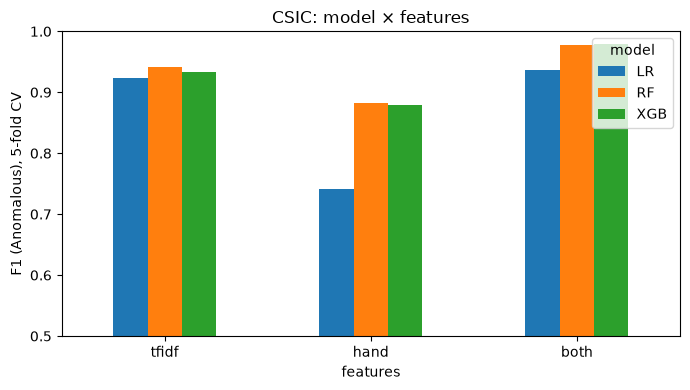

In [ ]:
ax = results.pivot(index='features', columns='model', values='f1_mean').loc[['tfidf', 'hand', 'both']].plot.bar(
    rot=0, figsize=(7, 4), ylim=(0.5, 1))
ax.set_ylabel('F1 (Anomalous), 5-fold CV')
ax.set_title('CSIC: model × features')
plt.tight_layout()

## 5. Best model on the test set

Take the highest CV F1, train it on the full training set, and evaluate once on the test set.

best: XGB + both
              precision    recall  f1-score   support

      Normal      0.949     0.994     0.971      1929
   Anomalous      0.996     0.967     0.982      3193

    accuracy                          0.977      5122
   macro avg      0.972     0.981     0.976      5122
weighted avg      0.978     0.977     0.977      5122



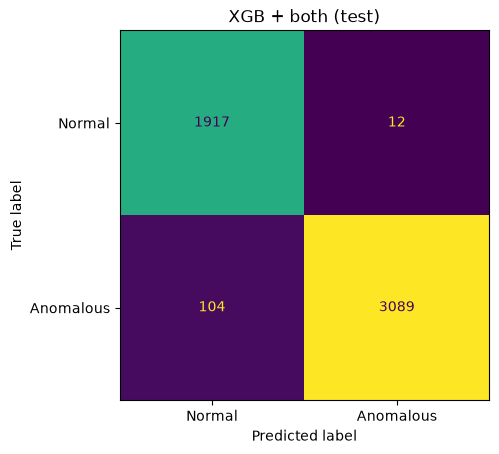

In [ ]:
best = results.sort_values('f1_mean', ascending=False).iloc[0]
print('best:', best['model'], '+', best['features'])
best_pipe = make_pipe(best['model'], best['features']).fit(X_train, y_train)
pred = best_pipe.predict(X_test)
print(classification_report(y_test, pred, target_names=['Normal', 'Anomalous'], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Normal', 'Anomalous'], colorbar=False)
plt.title(f"{best['model']} + {best['features']} (test)");

## 6. Most important features.py features (XGBoost)

Shows which of our hand-written features the model relies on.

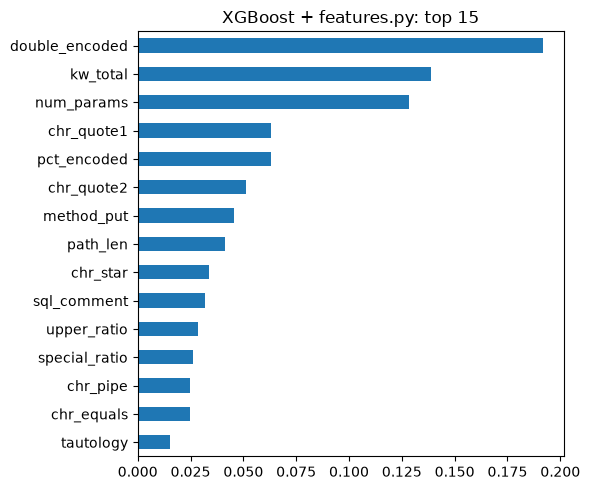

In [ ]:
xgb_hand = make_pipe('XGB', 'hand').fit(X_train, y_train)
imp = pd.Series(xgb_hand.named_steps['model'].feature_importances_, index=HAND_COLS).sort_values()
imp.tail(15).plot.barh(figsize=(6, 5), title='XGBoost + features.py: top 15')
plt.tight_layout()

## 7. Notes

- Which model won, and by how much?
- How does `hand` alone compare with `tfidf`? If they are close, that is good news for the generalisation test, because `hand` does not memorise the CSIC site.
- Did `both` help?
- Next: test the same models on Juice Shop data (generalisation test, week 4).